# Разведочный анализ данных Yambda-50M

## Данные

В работе используется открытый датасет [Yambda](https://huggingface.co/datasets/yandex/yambda) от Яндекс Музыки - логи взаимодействий пользователей с треками. Пользователи и треки анонимизированы: о людях ничего не известно, кроме их истории действий.

Датасет выпущен в трех размерах (50M, 500M и 5B событий). Для исследования взята версия **50M**, где одна строка соответствует одному событию.

В документации для версии 50M:
- пользователей: 10 000
- треков: 934 057
- прослушиваний: 46 467 212


Правило: прослушивание считается засчитанным, если проиграно больше 50% трека.

Используемые таблицы:

| Таблица | Строк | Что содержит |
|---|---|---|
| listens | 46 467 212 | прослушивания треков |
| likes | 881 456 | лайки |
| dislikes | 107 776 | дизлайки |

Колонки:

- `uid` — анонимный идентификатор пользователя;
- `item_id` — анонимный идентификатор трека;
- `timestamp` — время события в секундах от общей точки отсчёта, округлённое до 5 секунд; настоящих дат нет;
- `is_organic` — источник взаимодействия: 1 — пользователь нашёл трек сам, 0 — трек пришёл из рекомендаций;
- `played_ratio_pct` — какая часть трека прослушана, в процентах; может превышать 100, если трек перематывали и переслушивали (только в listens);
- `track_length_seconds` — длительность трека в секундах (только в listens).

Таблицы связываются между собой через `uid` и `item_id`.

## Цель этого ноутбука

Понять, как выглядит обычное поведение пользователей: сколько и как долго они слушают, как прослушивания распределены во времени, насколько различается органическое и рекомендательное потребление. Это нужно, чтобы дальше отличать норму от аномалий.

## Содержание
1. Общая информация и пользователи без прослушиваний
2. Типы колонок и пропуски
3. Быстрые пропуски: органика и рекомендации, распределение по пользователям
4. Длины треков и дослушивание
5. Распределение прослушиваний по времени
6. Итоги

In [39]:
import polars as pl
import matplotlib.pyplot as plt

listens = pl.read_parquet("../data/listens.parquet")

In [40]:
listens.head()

uid,timestamp,item_id,is_organic,played_ratio_pct,track_length_seconds
u32,u32,u32,u8,u16,u32
100,39420,8326270,0,100,170
100,39420,1441281,0,100,105
100,39625,286361,0,100,185
100,40110,732449,0,100,240
100,40360,3397170,0,46,130


In [41]:
listens.shape

(46467212, 6)

В таблице listens 46 467 212 прослушиваний и 6 колонок.

In [42]:
listens['uid'].unique().len()

9238

Количество пользователей, у которых есть прослушивания — 9 238, тогда как по документации в датасете 10 000 пользователей. Значит, у 762 пользователей нет ни одного прослушивания: возможно, они ставили лайки или дизлайки, ничего не слушая

In [43]:
likes = pl.read_parquet("../data/likes.parquet")
dislikes = pl.read_parquet("../data/dislikes.parquet")

print(likes["uid"].n_unique(), dislikes["uid"].n_unique())

all_users = pl.concat([listens["uid"], likes["uid"], dislikes["uid"]]).n_unique()
print(all_users)

8283 5951
10000


In [44]:
listeners = listens["uid"].unique().to_frame()

likes_no_listen = likes.join(listeners, on="uid", how="anti")
dislikes_no_listen = dislikes.join(listeners, on="uid", how="anti")
print(likes_no_listen["uid"].n_unique())
print(dislikes_no_listen["uid"].n_unique())

760
647


In [45]:
like_users = likes_no_listen.select("uid").unique()
dislike_users = dislikes_no_listen.select("uid").unique()

both = like_users.join(dislike_users, on="uid", how="inner")
print(both.height)

645


### Пользователи без прослушиваний

В listens встречается 9 238 пользователей из 10 000. У оставшихся 762 нет ни одного прослушивания, но есть другие действия: 760 человек ставили лайки, 647 — дизлайки (645 пользователей делали и то, и другое). То есть эти пользователи оценивают треки, не слушая их, если ориентироваться только на имеющиеся данные

Возможные объяснения:
- прослушивания были, но не попали в датасет (другой период, другое устройство)
- пользователь оценивает треки по названию или превью, не включая их полностью
- это нетипичное или автоматическое поведение, например накрутка лайков

По одним этим данным различить эти варианты нельзя. Дальше стоит посмотреть, сколько оценок ставит каждый такой пользователь и как они распределены во времени: несколько лайков выглядят естественно, а сотни лайков за короткий период без прослушиваний - аномалия


In [46]:
listens.schema

Schema([('uid', UInt32),
        ('timestamp', UInt32),
        ('item_id', UInt32),
        ('is_organic', UInt8),
        ('played_ratio_pct', UInt16),
        ('track_length_seconds', UInt32)])

### Типы колонок и перевод timestamp

Все числовые колонки в датасете хранятся в беззнаковых целочисленных типах (`UInt8`, `UInt16`, `UInt32`). «Беззнаковый» означает, что тип хранит только неотрицательные числа, без минуса. Цифра показывает, сколько бит отведено под значение. Например, `UInt32` вмещает числа от 0 до примерно 4,3 млрд. В датасете к каждой колонке был подобран минимальный подходящий тип, чтобы данные занимали меньше памяти.

Для `timestamp` это создает проблему. Дальше нужно будет считать паузы между событиями как разницу соседних значений времени. В беззнаковом типе результат вычитания не может быть отрицательным: если он уходит в минус, вместо отрицательного числа получается огромное положительное (переполнение), и расчет ломается, поэтому нужно перевести `timestamp` в знаковый тип `Int64`, который хранит и отрицательные числа. Цена - колонка займет вдвое больше памяти (8 байт на значение вместо 4), для 46 млн строк это около 190 МБ дополнительно.

In [47]:
listens = listens.with_columns(
    pl.col("timestamp").cast(pl.Int64)
).with_columns(
    pl.col("timestamp").alias("ts_sec"),
    (pl.col("timestamp") // 86400).alias("day"),
    ((pl.col("timestamp") % 86400) // 3600).alias("hour"),
)
listens.schema

Schema([('uid', UInt32),
        ('timestamp', Int64),
        ('item_id', UInt32),
        ('is_organic', UInt8),
        ('played_ratio_pct', UInt16),
        ('track_length_seconds', UInt32),
        ('ts_sec', Int64),
        ('day', Int64),
        ('hour', Int64)])

аналогично для likes и dislikes

In [48]:
likes = likes.with_columns(pl.col("timestamp").cast(pl.Int64))
dislikes = dislikes.with_columns(pl.col("timestamp").cast(pl.Int64))
print('likes: ', likes.schema)
print('dislikes: ', dislikes.schema)

likes:  Schema({'uid': UInt32, 'timestamp': Int64, 'item_id': UInt32, 'is_organic': UInt8})
dislikes:  Schema({'uid': UInt32, 'timestamp': Int64, 'item_id': UInt32, 'is_organic': UInt8})


In [49]:
listens.null_count()

uid,timestamp,item_id,is_organic,played_ratio_pct,track_length_seconds,ts_sec,day,hour
u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0


### Скрытые пропуски

Проверка `null_count` показала, что пустых значений в данных нет. Однако пропуск может быть закодирован не пустой ячейкой, а нулем: например, если длина трека неизвестна, в колонке может стоять 0.

**Гипотеза:** часть значений `track_length_seconds` (длина треков в секундах) равна нулю, и это замаскированные пропуски

In [50]:
listens.filter(pl.col("track_length_seconds") == 0).height

0

In [51]:
listens["track_length_seconds"].min()

5

In [52]:
listens["track_length_seconds"].max()

2495

**Результат:** таких прослушиваний нет. Длина трека известна для всех событий, минимальная длина — 5 секунд, максимальная — 2 495 секунд (примерно 41,5 минуты). Гипотеза не подтвердилась.

**Дальше:** нужно проверить есть ли нули в `played_ratio_pct` (процент прослушивания одного трека) и что они означают.

### Нулевое дослушивание

**Гипотеза:** прослушивания с `played_ratio_pct = 0` — это быстрые пропуски: трек включили и сразу переключили.

**Альтернативная гипотеза:** `played_ratio_pct` хранится целым числом процентов, поэтому все, что меньше 1% трека, записывается как 0. Для длинного трека 1% — это уже заметное время (для двухчасового трека около 72 секунд). Тогда часть нулей может быть настоящими прослушиваниями длинных треков, а не пропусками. Максимум в данных 2495 с, поэтому 1% от максимальной длины терка - 24,95 секунд

**Проверка:** нужно посчитать число нулевых прослушиваний и посмотреть, какой длины у них треки. Затем оценить верхнюю границу реально прослушанного времени: меньше 1% длины трека, то есть `track_length_seconds / 100`.

In [53]:
zero = listens.filter(pl.col("played_ratio_pct") == 0)
print("нулевых прослушиваний:", zero.height)
print("доля от всех:", round(zero.height / listens.height * 100, 2), "%")

нулевых прослушиваний: 3461280
доля от всех: 7.45 %


In [54]:
zero["track_length_seconds"].describe()

statistic,value
str,f64
"""count""",3.46128e6
"""null_count""",0.0
"""mean""",228.943927
"""std""",128.036034
"""min""",5.0
"""25%""",180.0
"""50%""",215.0
"""75%""",250.0
"""max""",2495.0


In [55]:
listens["track_length_seconds"].describe()

statistic,value
str,f64
"""count""",4.6467212e7
"""null_count""",0.0
"""mean""",207.411753
"""std""",89.210895
"""min""",5.0
"""25%""",165.0
"""50%""",200.0
"""75%""",230.0
"""max""",2495.0


In [56]:
zero = zero.with_columns((pl.col("track_length_seconds") / 100).alias("max_listened_sec"))
zero["max_listened_sec"].describe()

statistic,value
str,f64
"""count""",3.46128e6
"""null_count""",0.0
"""mean""",2.289439
"""std""",1.28036
"""min""",0.05
"""25%""",1.8
"""50%""",2.15
"""75%""",2.5
"""max""",24.95


**Результат:** прослушиваний с нулевым дослушиванием 3 461 280, 7,45% всех событий.

Длина треков по всем прослушиваниям: медиана 200 с, половина треков от 165 до 230 с, максимум 2 495 с (~41,5 минуты). Многочасовых треков в данных нет.

Верхняя граница реально прослушанного времени у нулевых прослушиваний: медиана 2,15 с, 75% — не больше 2,5 с, максимум — меньше 25 с.

**Вывод:** подтвердилась первая гипотеза: нулевое дослушивание почти всегда означает быстрый пропуск. Альтернативная гипотеза не подтвердилась: даже для самых длинных треков «0%» — это меньше 25 секунд, а в типичном случае пара секунд.

Дополнительно: средняя длина сразу пропущенных треков (229 с, примерно 3,8 минуты) немного выше средней длины трека по всем прослушиваниям (207 с).

### Быстрые пропуски: органика и рекомендации

**Гипотеза:** быстрые пропуски (`played_ratio_pct = 0`) чаще встречаются в рекомендательном потреблении (`is_organic = 0`), чем в органическом (`is_organic = 1`).

**Проверка:** для каждой группы считаем общее число прослушиваний, число быстрых пропусков и их долю.

In [57]:
listens.group_by("is_organic").agg(
    pl.len().alias("all_listens"),
    (pl.col("played_ratio_pct") == 0).sum().alias("zero_listens"),
    (pl.col("played_ratio_pct") == 0).mean().alias("zero_share"),
)

is_organic,all_listens,zero_listens,zero_share
u8,u32,u32,f64
1,24003657,2337480,0.09738
0,22463555,1123800,0.050028


**Результат:** гипотеза не подтвердилась. Доля быстрых пропусков в органическом потреблении почти вдвое выше, чем в рекомендательном: 9,7% против 5,0%. Объёмы групп: 24,0 млн органических и 22,5 млн рекомендательных прослушиваний.

**Возможные объяснения:**
- органическое потребление включает прослушивание собственной коллекции и плейлистов, где пользователь активно пролистывает треки, в том числе в режиме перемешивания
- при поиске пользователь может включить неподходящий результат и сразу переключить его
- рекомендательный поток чаще слушают фоном, не вмешиваясь
- рекомендательная система уже учитывает прошлые пропуски и реже предлагает нежелательные треки

По этим данным различить объяснения нельзя, но результат важен для дальнейшей работы: высокая доля пропусков сама по себе не признак аномалии и зависит от источника прослушивания. При поиске аномалий признаки стоит считать отдельно для органики и рекомендаций.

### Пользователи с высокой долей быстрых пропусков

**Гипотеза:** у большинства пользователей доля быстрых пропусков невелика, но есть отдельные пользователи, у которых почти все прослушивания — мгновенные пропуски. Такое поведение нетипично и может быть кандидатом в аномалии.

**Проверка:** для каждого пользователя посчитать число прослушиваний и долю быстрых пропусков, посмотреть распределение этой доли и самых крайних пользователей. Пользователей с очень малым числом прослушиваний не нужно учитывать: при 3 прослушиваниях доля 100% ничего не говорит.

In [58]:
users_skip = listens.group_by("uid").agg(
    pl.len().alias("n_listens"),
    (pl.col("played_ratio_pct") == 0).mean().alias("zero_share"),
)
users_skip.head()

uid,n_listens,zero_share
u32,u32,f64
858200,7206,0.045518
598000,323,0.06192
813100,4465,0.022844
515800,7029,0.534927
547300,2440,0.052459


In [59]:
users_skip["zero_share"].describe()

statistic,value
str,f64
"""count""",9238.0
"""null_count""",0.0
"""mean""",0.064909
"""std""",0.081029
"""min""",0.0
"""25%""",0.012821
"""50%""",0.037362
"""75%""",0.08654
"""max""",1.0


**Результат:** у типичного пользователя быстрые пропуски составляют небольшую часть прослушиваний: медиана 3,7%, у 75% пользователей — не больше 8,7%. Распределение скошено вправо: среднее (6,5%) выше медианы, то есть есть пользователи с заметно большей долей пропусков. Максимум — 100%, но это может быть пользователь с очень малым числом прослушиваний, поэтому крайних пользователей смотрим только среди тех, у кого 100 и больше прослушиваний.


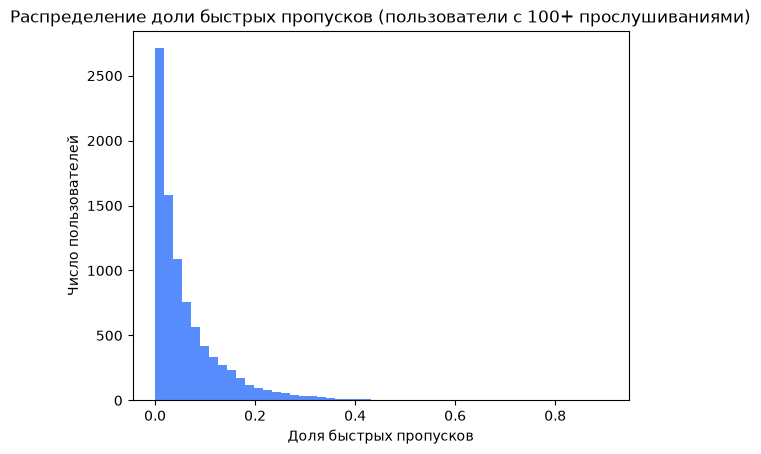

In [60]:
active = users_skip.filter(pl.col("n_listens") >= 100) # только пользователи со 100 и более прослушиваниями

plt.hist(active["zero_share"], bins=50)
plt.xlabel("Доля быстрых пропусков")
plt.ylabel("Число пользователей")
plt.title("Распределение доли быстрых пропусков (пользователи с 100+ прослушиваниями)")
plt.show()

**Результат:** распределение доли быстрых пропусков среди активных пользователей (100+ прослушиваний) сильно скошено. Наибольшая группа — пользователи, которые почти никогда не пропускают треки сразу (около 2 700 человек с долей до 2%). Дальше число пользователей плавно убывает, без новых пиков. Значит, обособленной группы пользователей, которые постоянно пропускают треки, нет: пользователи с высокой долей пропусков — просто самые крайние в общем распределении.

Почти все пользователи пропускают сразу не больше 40% треков. При этом ось распределения доходит примерно до 0,9: существуют единичные пользователи с очень высокой долей пропусков, которые на графике не видны из-за малого числа. Их стоит разобрать подробнее.

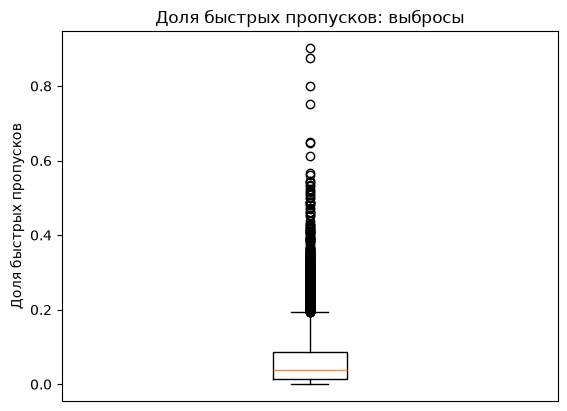

In [61]:
plt.boxplot(active["zero_share"].to_numpy(), orientation="vertical")
plt.ylabel("Доля быстрых пропусков")
plt.xticks([])
plt.title("Доля быстрых пропусков: выбросы")
plt.show()

**Результат:** по стандартному правилу (1,5 межквартильного размаха) выбросами считается большое число пользователей с долей пропусков выше 0,2. Это следствие сильной асимметрии распределения: правило рассчитано на симметричные данные, и для длинного хвоста оно слишком строгое.

Точки до ~0,56 образуют непрерывную полосу, это продолжение хвоста распределения. Выше видно несколько пользователей, заметно оторвавшихся от остальных (доля пропусков 0,6–0,9). Их рассматриваем как кандидатов в аномалии.


In [62]:
users_skip["n_listens"].describe()

statistic,value
str,f64
"""count""",9238.0
"""null_count""",0.0
"""mean""",5030.007794
"""std""",5520.14541
"""min""",6.0
"""25%""",937.0
"""50%""",3024.0
"""75%""",7182.0
"""max""",27617.0


**Активность пользователей:** число прослушиваний на пользователя сильно различается: от 6 до 27 617. Медиана — 3 024, среднее — 5 030; среднее выше медианы из-за небольшой группы очень активных пользователей. Половина пользователей имеет от 937 до 7 182 прослушиваний.


### Длины треков

**Гипотеза:** большинство треков — обычные песни длиной 2–5 минут; длинные треки (подкасты, миксы) встречаются редко.

**Проверка:** строим гистограмму длины трека по всем прослушиваниям.

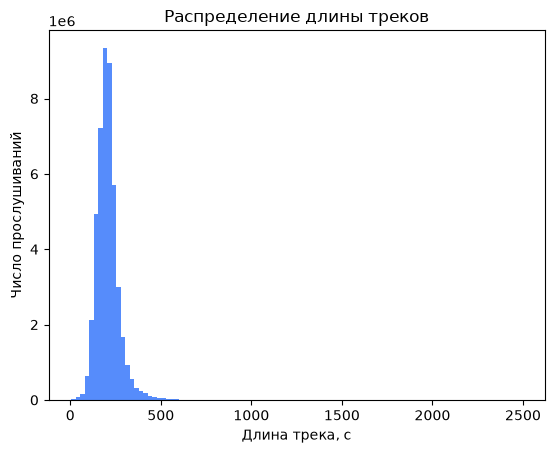

In [63]:
plt.hist(listens["track_length_seconds"], bins=100)
plt.xlabel("Длина трека, с")
plt.ylabel("Число прослушиваний")
plt.title("Распределение длины треков")
plt.show()

**Результат:** гипотеза подтвердилась. Подавляющее большинство прослушиваний приходится на треки длиной примерно от 2 до 5 минут, пик — около 3–3,5 минут (200 с), что соответствует обычной длине песни. Распределение немного скошено: после 5 минут число прослушиваний быстро падает, а треки длиннее 8 минут (500 с) встречаются единично и на графике практически не видны, хотя максимальная длина достигает 2 495 с (41,5 минуты).

Значит, данные в основном состоят из обычных песен, а длинные записи (миксы, подкасты) составляют малую долю и не влияют на общую картину.

In [64]:
(listens["track_length_seconds"] > 600).mean() * 100

0.28942343259156583

**Результат:** треки длиннее 10 минут дают всего 0,3% прослушиваний. Длинные записи действительно почти не встречаются, и дальше их можно не выделять отдельно.

### Дослушивание

**Гипотеза:** большая часть треков дослушивается до конца (около 100%), но заметная доля прослушиваний не засчитывается (меньше 50%), а часть превышает 100% из-за перемотки.

**Проверка:** гистограмма `played_ratio_pct` и доли трёх групп: меньше 50%, от 50 до 100%, больше 100%.

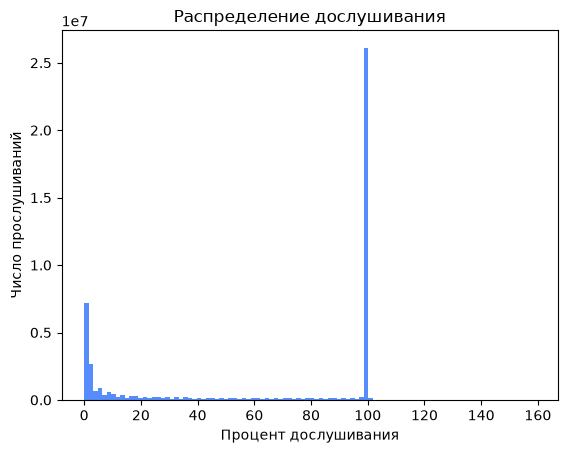

In [65]:
plt.hist(listens["played_ratio_pct"].clip(upper_bound=200), bins=100)
plt.xlabel("Процент дослушивания")
plt.ylabel("Число прослушиваний")
plt.title("Распределение дослушивания")
plt.show()

In [66]:
listens.select(
    (pl.col("played_ratio_pct") < 50).mean().alias("не засчитано (<50%)"),
    ((pl.col("played_ratio_pct") >= 50) & (pl.col("played_ratio_pct") <= 100)).mean().alias("50–100%"),
    (pl.col("played_ratio_pct") > 100).mean().alias("больше 100%"),
    pl.col("played_ratio_pct").max().alias("максимум"),
)

не засчитано (<50%),50–100%,больше 100%,максимум
f64,f64,f64,u16
0.366451,0.628855,0.004695,159


**Результат:** распределение дослушивания двугорбое. Самый большой пик — ровно на 100% (около 26 млн прослушиваний, больше половины всех), второй — быстрые пропуски в первые проценты трека. Промежуточные значения встречаются редко и распределены почти равномерно. Пользователи ведут себя по принципу «всё или ничего»: либо пропускают трек в начале, либо дослушивают его до конца.

Доли прослушиваний:
- меньше 50% (не засчитано) — 36,6%;
- от 50 до 100% — 62,9%;
- больше 100% (перемотка и повтор) — 0,5%, максимум — 159%.

Гипотеза подтвердилась частично. Большая часть треков действительно дослушивается, но доля незасчитанных прослушиваний оказалась высокой: больше трети всех событий. Из них около 7,45 процентного пункта приходятся на мгновенные пропуски (0%), остальное — на пропуски в первые секунды и редкие обрывы в середине. Перемотки, напротив, встречаются крайне редко.

Резкий пик ровно на 100%, без плавного подъёма перед ним, говорит о том, что полностью прослушанный трек записывается сервисом как ровно 100%.

 Для дальнейшей работы: обычное поведение пользователей — «всё или ничего»: трек либо пропускается в первые секунды, либо дослушивается до конца, а промежуточные значения редки. Это помогает искать аномалии. Бот для накрутки заинтересован, чтобы прослушивание засчиталось, при минимальных затратах времени, поэтому он может слушать ровно столько, сколько нужно для засчитывания (чуть больше 50% трека), и переключать трек. У живых пользователей такого скопления прослушиваний сразу за порогом нет. Поэтому возможные признаки: доля прослушиваний в узком диапазоне сразу после 50% и разброс реально прослушанного времени (у бота он может быть подозрительно мал). Боты, которые дослушивают треки до конца, по этому признаку не отличаются от людей, и для них нужны другие признаки — например, длительность непрерывной активности и регулярность пауз.

### Распределение прослушиваний по времени

**Что такое `timestamp`.** Время события задано не датой, а числом секунд от некоторой точки отсчёта. Сама точка отсчёта неизвестна — настоящие даты скрыты. Время округлено до 5 секунд: в документации сказано «binned into 5s units», и все значения в данных кратны 5. Точность времени — 5 секунд: события внутри одного 5-секундного окна имеют одинаковый `timestamp`.

**Что из этого можно извлечь.** Абсолютное время (реальная дата, день недели, час суток) недоступно. Зато доступны:
- разница между событиями — паузы между прослушиваниями, длина сессий
- условный номер дня от начала отсчёта — можно увидеть, за какой период собраны данные и как меняется активность
- условный час внутри суток — реальное время суток неизвестно, но если ночью слушают меньше, суточный ритм будет виден как провал на графике

**Что делаем.** Переводим `timestamp` в секунды, затем в условный день и час:
- `day = ts_sec // 86400` — номер дня (в сутках 86 400 секунд)
- `hour = (ts_sec % 86400) // 3600` — номер часа внутри суток

**Гипотезы:**
- данные охватывают продолжительный период (несколько месяцев)
- в прослушиваниях виден суточный ритм: в одни часы слушают заметно меньше (условная ночь)
- возможен недельный ритм (будни и выходные)

In [67]:
print("первый день:", listens["day"].min())
print("последний день:", listens["day"].max())
print("период, дней:", listens["day"].max() - listens["day"].min() + 1)

первый день: 0
последний день: 300
период, дней: 301


Посмотрим, как число прослушиваний меняется по дням.

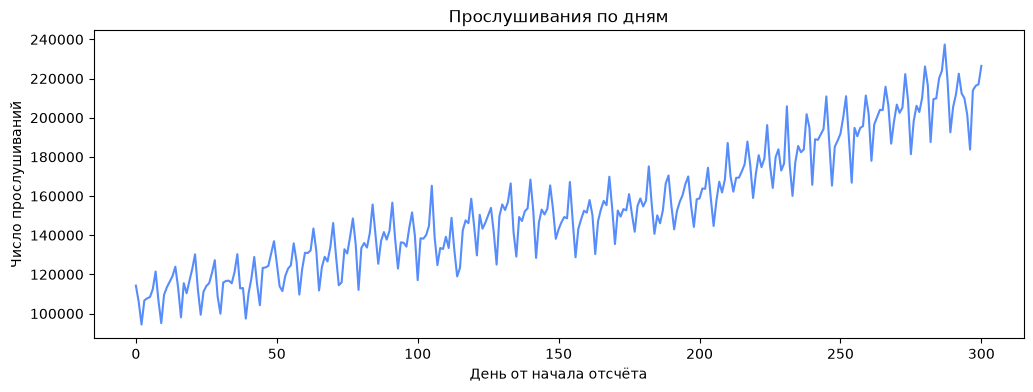

In [68]:
per_day = listens.group_by("day").len().sort("day")

plt.figure(figsize=(12, 4))
plt.plot(per_day["day"], per_day["len"])
plt.xlabel("День от начала отсчёта")
plt.ylabel("Число прослушиваний")
plt.title("Прослушивания по дням")
plt.show()

**Результат:** данные охватывают около 300 дней (~10 месяцев). Все три гипотезы подтвердились.

- **Рост активности.** Число прослушиваний в день почти линейно растёт: от ~110 тыс. в начале периода до ~210 тыс. в конце, почти вдвое. Причиной может быть как рост использования сервиса, так и особенность отбора пользователей в выборку. Для поиска аномалий это важно: обычный уровень активности меняется со временем, поэтому сравнивать пользователя стоит с поведением других пользователей в тот же период.
- **Недельный ритм.** Хорошо видна периодичность в 7 дней: в течение недели активность растёт, а затем резко падает на один-два дня. Вероятно, это переход между буднями и выходными. Какие именно это дни недели, определить нельзя, так как реальные даты скрыты.
- Резких одиночных всплесков, выбивающихся из общего ритма, не видно: на уровне всего сервиса явных аномальных дней нет.

На графике по дням видны падения с периодом 7 дней. Чтобы увидеть недельный ритм нагляднее, сгруппируем прослушивания по условному дню недели (`day % 7`).

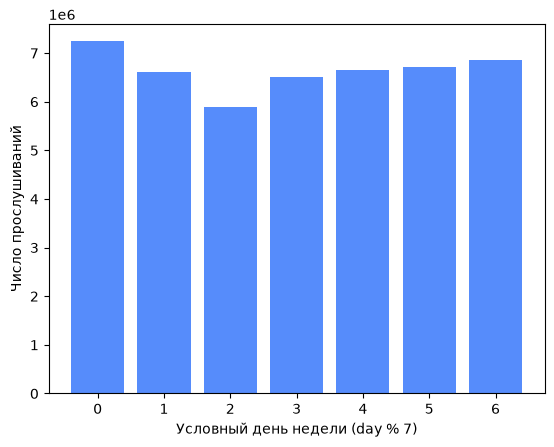

shape: (7, 2)
┌─────┬─────────┐
│ day ┆ len     │
│ --- ┆ ---     │
│ i64 ┆ u32     │
╞═════╪═════════╡
│ 0   ┆ 7238458 │
│ 1   ┆ 6617120 │
│ 2   ┆ 5887472 │
│ 3   ┆ 6515155 │
│ 4   ┆ 6645852 │
│ 5   ┆ 6709880 │
│ 6   ┆ 6853275 │
└─────┴─────────┘


In [69]:
per_weekday = listens.group_by(pl.col("day") % 7).len().sort("day")
plt.bar(per_weekday["day"], per_weekday["len"])
plt.xlabel("Условный день недели (day % 7)")
plt.ylabel("Число прослушиваний")
plt.show()
print(per_weekday)

**Результат:** при группировке по условному дню недели (`day % 7`) недельный ритм подтверждается: самый активный условный день — 0 (7,24 млн прослушиваний), самый тихий — 2 (5,9 млн), разница около 19%. От дня 3 к дню 0 активность постепенно растёт, а после пика за один-два дня падает до минимума. На графике по дням этот же эффект выглядел сильнее, потому что ось начиналась не с нуля. Соответствие условных дней реальным дням недели неизвестно, но можно предположить, что провал (дни 1–2) соответствует выходным.

Осталась последняя гипотеза — суточный ритм. Сгруппируем прослушивания по условному часу суток.

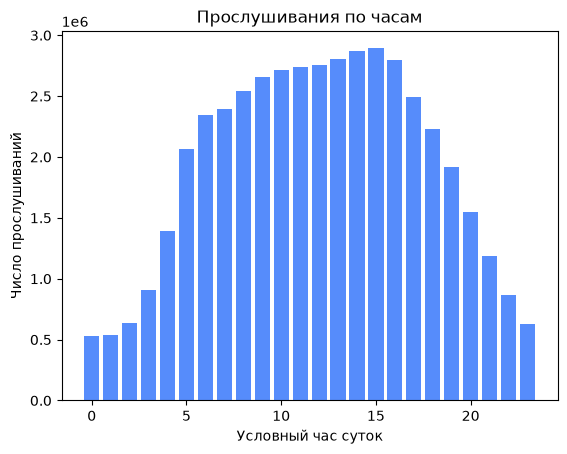

In [70]:
per_hour = listens.group_by("hour").len().sort("hour")

plt.bar(per_hour["hour"], per_hour["len"])
plt.xlabel("Условный час суток")
plt.ylabel("Число прослушиваний")
plt.title("Прослушивания по часам")
plt.show()

**Результат:** суточный ритм хорошо выражен. Минимум активности приходится на условные часы 0–2 (около 0,53 млн прослушиваний за час), с 3 до 6 часов активность резко растёт, с 9 до 16 держится на высоком уровне с пиком в 15 часов (около 2,9 млн), а затем плавно снижается к 23 часам. Разница между пиком и минимумом — примерно в 5,5 раза.

Реальное время суток неизвестно, но форма графика соответствует обычному дню: условные часы 0–2 — ночь. Если считать, что отсчёт часов совпадает с UTC, то минимум приходится на 3–5 утра, утренний подъём — на 7–9 часов, а пик — на 18 часов, что правдоподобно для сервиса с российской аудиторией.

**Что это значит для поиска аномалий:** даже ночью прослушиваний немало (около 0,5 млн за час), поэтому само по себе ночное прослушивание не аномалия: люди слушают музыку перед сном или фоном. Подозрительным может быть другое — равномерная активность пользователя во все часы суток без «ночного» провала, характерного для всех остальных.

## Итоги разведочного анализа

**Данные.** Yambda-50M: 10 000 пользователей, 46,5 млн прослушиваний за 300 дней (10 месяцев), а также 881 тыс. лайков и 108 тыс. дизлайков. Пропусков нет. `timestamp` — секунды от неизвестной точки отсчёта, округлённые до 5 секунд; реальные даты скрыты.

**Главные наблюдения:**
1. **Пользователи без прослушиваний.** У 762 пользователей нет ни одного прослушивания, но есть лайки или дизлайки (645 из них ставили и то и другое).
2. **«Всё или ничего».** Распределение дослушивания двугорбое: трек либо пропускается в первые секунды, либо дослушивается до конца. 36,6% прослушиваний не засчитываются (меньше 50% трека), 7,45% — мгновенные пропуски; перемотки (больше 100%) почти не встречаются.
3. **Органика пропускается чаще.** Доля быстрых пропусков в органическом потреблении почти вдвое выше, чем в рекомендательном (9,7% против 5,0%), вопреки исходной гипотезе.
4. **Активность пользователей сильно различается.** От 6 до 27 617 прослушиваний, медиана — около 3 000. Доля быстрых пропусков у большинства невелика (медиана 3,7%), отдельные пользователи пропускают больше 60% треков.
5. **Временные ритмы.** Активность за период почти удваивается, видны недельный (7 дней) и суточный (минимум ночью, пик днём) ритмы.

**Выводы для дальнейшей работы:**
- признаки стоит считать с учётом источника прослушивания (органика / рекомендации), так как поведение в них различается;
- «нормальная» активность меняется во времени, поэтому пользователя стоит сравнивать с другими в тот же период;
- перспективные признаки для детекторов: доля быстрых пропусков, разброс времени прослушивания, наличие «ночного» провала в активности, лайки и дизлайки без прослушиваний.
- гипотеза для проверки: бот для накрутки может слушать трек ровно до порога засчитывания (чуть больше 50%), тогда у него будет скопление прослушиваний сразу за порогом, которого у живых пользователей быть не должно.

**Следующие шаги:** собрать таблицу признаков на уровне пользователя, разобрать самых крайних пользователей и описать типы синтетических аномалий для генератора.

